In [1]:
print("Welcome to CampusGraph!")


Welcome to CampusGraph!


In [50]:
import pandas as pd

In [51]:
students = pd.read_csv("data/students.csv")
students

,student_id,name,department,year
0,S001,Mary,CSE,2
1,S002,Rahul,CSE,2
2,S003,Anu,CSE,2
3,S004,Priya,CSE,2
4,S005,Arjun,CSE,3
5,S006,Meera,CSE,3
6,S007,Adithya,CSE,2
7,S008,Neha,CSE,3
8,S009,Vishnu,CSE,2
9,S010,Diya,CSE,3


In [52]:
skills = pd.read_csv("data/skills.csv")
courses = pd.read_csv("data/courses.csv")
projects = pd.read_csv("data/projects.csv")
student_projects = pd.read_csv("data/student_projects.csv")
interactions = pd.read_csv("data/interactions.csv")

In [53]:
print("Students:", len(students))
print("Skills:", len(skills))
print("Courses:", len(courses))
print("Projects:", len(projects))
print("Student-Project relationships:", len(student_projects))
print("Interactions:", len(interactions))

Students: 20
Skills: 80
Courses: 60
Projects: 8
Student-Project relationships: 20
Interactions: 36


## Build Student Network

In [54]:
import networkx as nx

In [56]:
G = nx.Graph()

# Add all students as nodes
for student_id in students["student_id"]:
    G.add_node(student_id)

# Add interactions as edges
for _, row in interactions.iterrows():
    G.add_edge(row["student1"], row["student2"], 
               interaction=row["interaction_type"])

In [57]:
print("Number of students:", G.number_of_nodes())
print("Number of connections:", G.number_of_edges())

Number of students: 20
Number of connections: 36


In [58]:
degree = dict(G.degree())

for student, connections in degree.items():
    print(student, ":", connections)

S001 : 4
S002 : 4
S003 : 5
S004 : 3
S005 : 4
S006 : 4
S007 : 3
S008 : 3
S009 : 4
S010 : 5
S011 : 4
S012 : 4
S013 : 3
S014 : 3
S015 : 3
S016 : 3
S017 : 2
S018 : 4
S019 : 3
S020 : 4


In [59]:
sorted_degree = sorted(degree.items(), key=lambda x: x[1], reverse=True)

print("Most connected students:")
for student, connections in sorted_degree[:5]:
    print(student, ":", connections)

Most connected students:
S003 : 5
S010 : 5
S001 : 4
S002 : 4
S005 : 4


In [60]:
degree_centrality = nx.degree_centrality(G)

top_centrality = sorted(
    degree_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)

print("Top 5 students by degree centrality:")
for student, score in top_centrality[:5]:
    print(student, ":", round(score, 3))
    

Top 5 students by degree centrality:
S003 : 0.263
S010 : 0.263
S001 : 0.211
S002 : 0.211
S005 : 0.211


In [61]:
student_names = dict(zip(students["student_id"], students["name"]))

print("Top 5 most connected students:")

for student, score in top_centrality[:5]:
    print(student_names[student], "(", student, "):", round(score, 3))

Top 5 most connected students:
Anu ( S003 ): 0.263
Diya ( S010 ): 0.263
Mary ( S001 ): 0.211
Rahul ( S002 ): 0.211
Arjun ( S005 ): 0.211


In [62]:
isolated_students = list(nx.isolates(G))

print("Number of isolated students:", len(isolated_students))

if isolated_students:
    print("Isolated students:")
    for student in isolated_students:
        print(student_names[student])
else:
    print("No isolated students found.")

Number of isolated students: 0
No isolated students found.


In [63]:
centrality_df = pd.DataFrame(
    top_centrality,
    columns=["student_id", "degree_centrality"]
)

centrality_df["name"] = centrality_df["student_id"].map(student_names)

centrality_df = centrality_df[
    ["student_id", "name", "degree_centrality"]
]

centrality_df.head(10)

,student_id,name,degree_centrality
0,S003,Anu,0.263158
1,S010,Diya,0.263158
2,S001,Mary,0.210526
3,S002,Rahul,0.210526
4,S005,Arjun,0.210526
5,S006,Meera,0.210526
6,S009,Vishnu,0.210526
7,S011,Akhil,0.210526
8,S012,Sneha,0.210526
9,S018,Kiran,0.210526


In [64]:
from networkx.algorithms.community import greedy_modularity_communities

communities = list(greedy_modularity_communities(G))

print("Number of communities:", len(communities))

for i, community in enumerate(communities, start=1):
    print("\nCommunity", i)
    for student in sorted(community):
        print(student_names[student], end=", ")

Number of communities: 4

Community 1
Priya, Neha, Diya, Joel, Devika, Anjali, 
Community 2
Arjun, Akhil, Amal, Isha, Kiran, 
Community 3
Anu, Meera, Sneha, Rohan, Nikhil, 
Community 4
Mary, Rahul, Adithya, Vishnu, 

In [65]:
source = "S003"
target = "S010"

if nx.has_path(G, source, target):
    path = nx.shortest_path(G, source, target)

    print("Shortest path:")
    print(" -> ".join(student_names[student] for student in path))

    print("Number of connections:", len(path) - 1)
else:
    print("No path exists between these students.")

Shortest path:
Anu -> Diya
Number of connections: 1


In [66]:
components = list(nx.connected_components(G))

print("Number of connected groups:", len(components))

for i, component in enumerate(components, start=1):
    print("Group", i, ":", len(component), "students")

Number of connected groups: 1
Group 1 : 20 students


In [67]:
student_skills = skills.groupby("student_id")["skill"].apply(set).to_dict()

print("Mary's skills:")
print(student_skills["S001"])

Mary's skills:
{'SQL', 'NetworkX', 'Data Analysis', 'Python'}


In [70]:
def recommend_new_collaborators(student_id, top_n=5):
    recommendations = []

    current_skills = student_skills.get(student_id, set())

    for other_id, other_skills in student_skills.items():
        if other_id == student_id:
            continue

        # Skip students already directly connected
        if G.has_edge(student_id, other_id):
            continue

        common_skills = current_skills & other_skills
        score = len(common_skills)

        if score > 0:
            recommendations.append(
                (other_id, score, common_skills)
            )

    recommendations.sort(key=lambda x: x[1], reverse=True)

    return recommendations[:top_n]

In [73]:
print("Top collaborator recommendations for Mary:\n")

for i, (student_id, score, common_skills) in enumerate(recommendations, start=1):
    print(f"{i}. {student_names[student_id]} ({student_id})")
    print(f"   Shared skills: {', '.join(sorted(common_skills))}")
    print(f"   Compatibility score: {score}")
    print()

Top collaborator recommendations for Mary:

1. Vishnu (S009)
   Shared skills: Data Analysis, NetworkX, Python, SQL
   Compatibility score: 4

2. Devika (S015)
   Shared skills: Data Analysis, NetworkX, Python, SQL
   Compatibility score: 4

3. Meera (S006)
   Shared skills: Data Analysis, Python, SQL
   Compatibility score: 3

4. Akhil (S011)
   Shared skills: NetworkX, Python, SQL
   Compatibility score: 3

5. Joel (S013)
   Shared skills: NetworkX, Python, SQL
   Compatibility score: 3



## Network Visualization

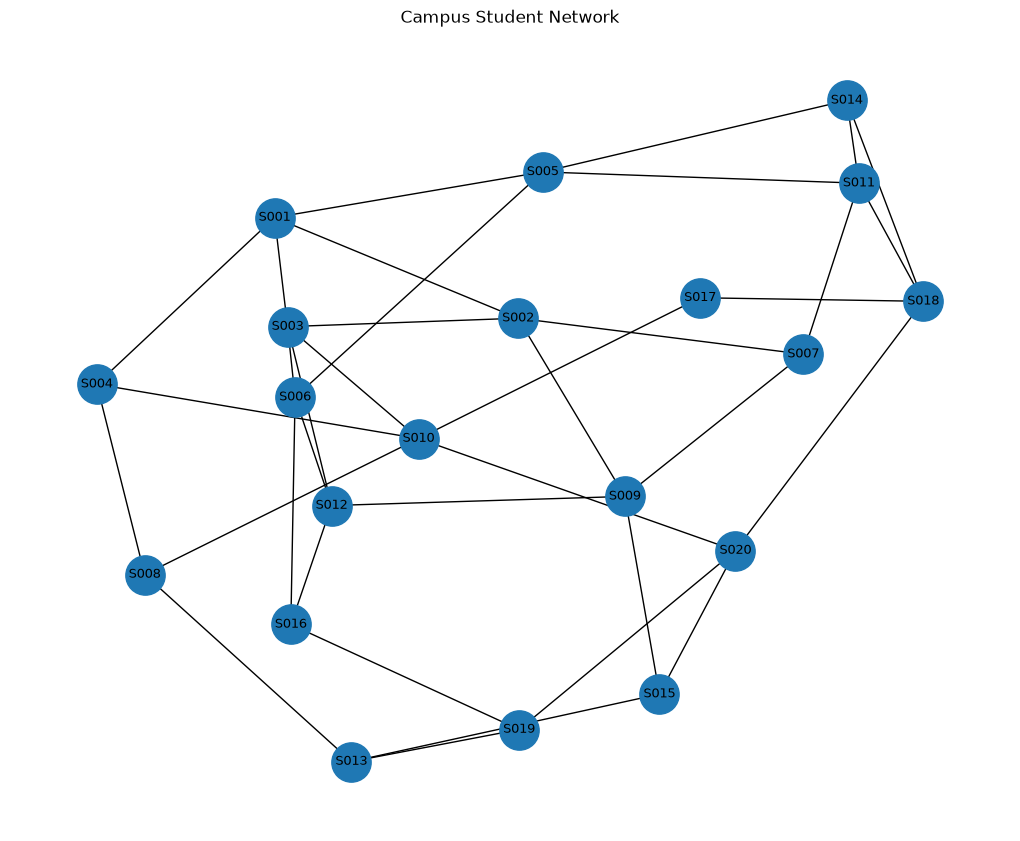

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=800,
    font_size=9
)

plt.title("Campus Student Network")
plt.show()

## Database Integration

In [75]:
import sqlite3

conn = sqlite3.connect("campus.db")

students.to_sql("students", conn, if_exists="replace", index=False)
skills.to_sql("skills", conn, if_exists="replace", index=False)
courses.to_sql("courses", conn, if_exists="replace", index=False)
projects.to_sql("projects", conn, if_exists="replace", index=False)
student_projects.to_sql("student_projects", conn, if_exists="replace", index=False)
interactions.to_sql("interactions", conn, if_exists="replace", index=False)

print("All datasets stored in SQLite database successfully.")

All datasets stored in SQLite database successfully.


In [76]:
query = "SELECT * FROM students LIMIT 5"

result = pd.read_sql_query(query, conn)

result

,student_id,name,department,year
0,S001,Mary,CSE,2
1,S002,Rahul,CSE,2
2,S003,Anu,CSE,2
3,S004,Priya,CSE,2
4,S005,Arjun,CSE,3


In [77]:
# Find students from CSE who are in Year 3

query = """
SELECT student_id, name, department, year
FROM students
WHERE year = 3
"""

year3_students = pd.read_sql_query(query, conn)

year3_students

,student_id,name,department,year
0,S005,Arjun,CSE,3
1,S006,Meera,CSE,3
2,S008,Neha,CSE,3
3,S010,Diya,CSE,3
4,S012,Sneha,CSE,3
5,S014,Amal,CSE,3
6,S016,Rohan,CSE,3
7,S018,Kiran,CSE,3
8,S020,Anjali,CSE,3


In [78]:
# Count students by year

query = """
SELECT year, COUNT(*) AS student_count
FROM students
GROUP BY year
ORDER BY year
"""

student_count = pd.read_sql_query(query, conn)

student_count

,year,student_count
0,2,11
1,3,9


In [79]:
# Create a table containing student connectivity information

network_analysis = pd.DataFrame({
    "student_id": list(degree.keys()),
    "degree": list(degree.values())
})

network_analysis["name"] = network_analysis["student_id"].map(student_names)
network_analysis["degree_centrality"] = network_analysis["student_id"].map(degree_centrality)

network_analysis = network_analysis[
    ["student_id", "name", "degree", "degree_centrality"]
]

network_analysis = network_analysis.sort_values(
    "degree_centrality",
    ascending=False
)

network_analysis.head(10)

,student_id,name,degree,degree_centrality
2,S003,Anu,5,0.263158
9,S010,Diya,5,0.263158
1,S002,Rahul,4,0.210526
0,S001,Mary,4,0.210526
10,S011,Akhil,4,0.210526
4,S005,Arjun,4,0.210526
8,S009,Vishnu,4,0.210526
5,S006,Meera,4,0.210526
17,S018,Kiran,4,0.210526
11,S012,Sneha,4,0.210526


## Project Summary

In [80]:
print("CampusGraph Project Summary")
print("----------------------------")
print("Total students:", G.number_of_nodes())
print("Total student connections:", G.number_of_edges())
print("Number of communities:", len(communities))
print("Number of isolated students:", len(isolated_students))

print("\nMost connected students:")

for student, score in top_centrality[:5]:
    print(
        student_names[student],
        "-",
        round(score, 3)
    )

CampusGraph Project Summary
----------------------------
Total students: 20
Total student connections: 36
Number of communities: 4
Number of isolated students: 0

Most connected students:
Anu - 0.263
Diya - 0.263
Mary - 0.211
Rahul - 0.211
Arjun - 0.211


In [81]:
conn.close()

print("Database connection closed.")

Database connection closed.
